## Load modules and libraries

In [1]:
# Load Java/JDK
# Load R/4.3.1

In [ ]:
# Load libraries
import numpy as np
import pandas as pd
import networkx as nx
from dowhy import gcm
from multiprocessing import Pool
import time
import pickle

#from rpy2.robjects import conversion, default_converter, pandas2ri
#from rpy2.robjects.conversion import localconverter
#from rpy2.robjects.packages import importr
#import rpy2.robjects as robjects

import os
import sys
sys.path.insert(1, os.path.join(os.environ['PYTETRAD_HOME'], 'pytetrad'))

import jpype.imports

try:
    jpype.startJVM(classpath=[os.path.join(os.environ['PYTETRAD_HOME'], 'pytetrad', 'resources', 'tetrad-current.jar')])
except OSError:
    print("JVM already started")

from coast.feature_selection import *
from coast.classify_variable_relationships import *
from coast.causal_graph_tetrad import *
#from coast.causal_graph_gcastle import *
from coast.causal_model import *
from coast.distribution_change_new import *
from coast.optimization import *
from coast.optimization_parallelization import *
from coast.pathway_analysis import *
from coast.utils import *

import matplotlib.pyplot as plt
import dowhy.utils.plotting as dowhy_plot

import warnings
warnings.filterwarnings("ignore")

## Data Preprocessing

### Load data

In [3]:
# Load global filtered data (genes x cells) and labels (cells x 2, one-hot: col0=MO, col1=OPC)
X = np.loadtxt('chen_X.txt')  # 1046 genes x 5282 cells
Y = np.loadtxt('chen_Y.txt')  # 5282 cells x 2 columns
gene_names = np.loadtxt('gene_names.txt', dtype=str)

# Split into OPC (source) and MO (target), transpose to cells x genes
mo_idx = Y[:, 0] == 1
opc_idx = Y[:, 1] == 1
X = X.T  # cells x genes

source_data_np = X[opc_idx, :]  # OPC cells
target_data_np = X[mo_idx, :]   # MO cells
print(f"Source (OPC): {source_data_np.shape[0]} cells x {source_data_np.shape[1]} genes")
print(f"Target (MO): {target_data_np.shape[0]} cells x {target_data_np.shape[1]} genes")

Source (OPC): 1741 cells x 1046 genes
Target (MO): 3541 cells x 1046 genes


In [4]:
# Define source state data (OPC) and target state data (MO) as DataFrames with gene names as columns
source_data = pd.DataFrame(source_data_np, columns=gene_names)
target_data = pd.DataFrame(target_data_np, columns=gene_names)
print(f"source_data: {source_data.shape}")
print(f"target_data: {target_data.shape}")
print(f"Columns aligned: {list(source_data.columns) == list(target_data.columns)}")

source_data: (1741, 1046)
target_data: (3541, 1046)
Columns aligned: True


In [2]:
# Define target_genes as DE genes from t-test (FDR<0.05 & |logFC|>2)
# Note: t-test and limma give exactly the same set of DE genes under these criteria
de_results = pd.read_csv('../de_results_ttest_global.csv')
target_genes = list(de_results[(de_results['p_bh'] < 0.05) & (de_results['log_fc'].abs() > 2)]['gene'])
print(f"Number of target genes (DE, FDR<0.05 & |logFC|>2): {len(target_genes)}")
print(f"First 10: {target_genes[:10]}")

Number of target genes (DE, FDR<0.05 & |logFC|>2): 262
First 10: ['Mtap7', 'Cldn11', 'Clic4', 'Pla2g16', 'Pip4k2a', 'Clu', 'Cmtm5', 'Pigz', 'Cnp', 'Cntn1']


### Feature selection

In [17]:
# Prepare and save data for feature selection
expression_data = pd.concat([source_data, target_data], axis=0)
# Add column names if none
cell_names = ['c'+str(i) for i in range(1,expression_data.shape[0]+1)]
expression_data.index = cell_names

expr_df = expression_data.transpose()
expr_df.to_csv("expression_data.csv", sep=",")

with open("targets.txt", "w") as f:
    for gene in target_genes:
        f.write(gene + "\n")

In [25]:
# Load prepared data and targets, and perform feature selection
expression_data = load_expression_data('expression_data.csv', index_col=0)
target_genes = load_target_genes('targets.txt')
run_pipeline(expression_data, target_genes, top_n1=5, top_n2=3, n_cores=30, k=7, n_trees=50, run_second_filtering=True, alpha=0.7)

Feature selection completed in 2930.17 seconds.


In [3]:
# Load data after feature selection
expression_data_1st_filtered = pd.read_csv('../Causal_Discovery_Dataset_1st_Level_Filtering.csv')
expression_data_2nd_filtered = pd.read_csv('../Causal_Discovery_Dataset_2nd_Level_Filtering.csv')
print(expression_data_1st_filtered.shape)
print(expression_data_2nd_filtered.shape)

# Define source state data and target state data, by splitting the dataframe
# In this example, we skipped the feature selection step and used the source_data and target_data defined above for downstream analyses

(5282, 290)
(5282, 263)


### Check relationships between variables

In [28]:
expression_data_2nd_filtered = pd.read_csv('Causal_Discovery_Dataset_2nd_Level_Filtering.csv')
results = classify_relationships_top_k(expression_data_2nd_filtered, k=100)
print(results)

{'Non-Linear with Non-Gaussian noise': '99.81%', 'Non-Linear with Gaussian noise': '0.19%'}


In [4]:
#expression_data_2nd_filtered = pd.read_csv('Causal_Discovery_Dataset_2nd_Level_Filtering.csv')
source_data = expression_data_2nd_filtered.iloc[:1741,:]
target_data = expression_data_2nd_filtered.iloc[1741:,:]

## Causal discovery and modeling

### Causal discovery

In [6]:
import pytetrad.tools.translate as tr
import edu.cmu.tetrad.algcomparison.algorithm.multi as multi
import edu.cmu.tetrad.util as util
import java.util as jutil

In [ ]:
# IMaGES uses the SEM BIC score by default, although it could use other scores.
alg = multi.Images()
params = util.Parameters()
params.set(util.Params.PENALTY_DISCOUNT, 2)
data = tr.pandas_data_to_tetrad(expression_data_2nd_filtered)

list = jutil.ArrayList()
list.add(data)
#list.add(data2)

cpdag = alg.search(list, params)

tr.print_java(cpdag)

In [9]:
from edu.cmu.tetrad.graph import GraphTransforms

# Assume 'cpdag' is your CPDAG object obtained from tetrad search
dag = GraphTransforms.dagFromCpdag(cpdag)

Starting Orientation Step D.
Orienting edge (Meek R1 triangle (Tprn-->Ppp1r14a---S1pr5)): Ppp1r14a --> S1pr5
Orienting edge (Meek R1 triangle (Tprn-->Ppp1r14a---Pigz)): Ppp1r14a --> Pigz
Orienting edge (Meek R1 triangle (Tprn-->Ppp1r14a---Agpat4)): Ppp1r14a --> Agpat4
Orienting edge (Meek R1 triangle (Tprn-->Ppp1r14a---Mobp)): Ppp1r14a --> Mobp
Orienting edge (Meek R1 triangle (Ppp1r14a-->Mobp---Csrp1)): Mobp --> Csrp1
Orienting edge (Meek R1 triangle (Tprn-->Ppp1r14a---Abca2)): Ppp1r14a --> Abca2
Orienting edge (Meek R1 triangle (Tprn-->Ppp1r14a---Adssl1)): Ppp1r14a --> Adssl1
Orienting edge (Meek R1 triangle (Ppp1r14a-->Mobp---Pdlim2)): Mobp --> Pdlim2
Orienting edge (Meek R1 triangle (Tprn-->Ppp1r14a---Gamt)): Ppp1r14a --> Gamt
Orienting edge (Meek R1 triangle (Mobp-->Csrp1---Pea15a)): Csrp1 --> Pea15a
Orienting edge (Meek R1 triangle (Ppp1r14a-->Mobp---Cldn11)): Mobp --> Cldn11
Orienting edge (Meek R1 triangle (Ppp1r14a-->Mobp---Tppp3)): Mobp --> Tppp3
Orienting edge (Meek R1 trian

In [10]:
text_file = open('cpdag.txt', 'w')
text_file.write(str(cpdag))
text_file.close()

In [11]:
text_file = open('dag.txt', 'w')
text_file.write(str(dag))
text_file.close()

In [ ]:
g3 = nx.DiGraph(get_edges('dag.txt'))

In [8]:
for col in expression_data_2nd_filtered.columns:
    if col not in g3.nodes():
        g3.add_node(col)

### Causal modeling

In [12]:
# Define a model (SCM) based on the causal graph
causal_model = gcm.StructuralCausalModel(g3)
# Assign causal mechanisms to each node (automatically)
# gcm.auto.assign_causal_mechanisms(causal_model, data)
custom_mechanisms(g3, causal_model)
# Fit the model to the data
gcm.fit(causal_model, source_data)

Fitting causal mechanism of node Slu7: 100%|██████████████████████████████████████████████████████████████████████████████████████████████| 263/263 [00:01<00:00, 185.89it/s]


## Optimization

In [13]:
# Initialization
causal_object = CausalClass(data_old=source_data, data_new=target_data, causal_graph=g3, causal_model=causal_model)
causal_object.get_total_changes()
causal_object.fit_old_model_on_new_data()

Total changes: 4076.589735450276


Fitting causal mechanism of node Slu7: 100%|██████████████████████████████████████████████████████████████████████████████████████████████| 263/263 [00:01<00:00, 193.26it/s]


### Root cause analysis

In [ ]:
savedir = '/path/to/save/results/'

In [14]:
mechanism_changes = causal_object.check_mechanism_changes()
with open('mechanism_changes.pkl', 'wb') as file:
    pickle.dump(mechanism_changes, file)

[Parallel(n_jobs=16)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:   39.8s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:  3.4min
[Parallel(n_jobs=16)]: Done 263 out of 263 | elapsed:  4.9min finished


Fitting for Rab6a
Fitting for Bex2
Fitting for Cdc37l1
Fitting for Pcbp4
Fitting for Plekhb1
Fitting for Sypl
Fitting for Sec11c
Fitting for Slc12a2
Fitting for Sox2ot
Fitting for Tmeff2
Fitting for Ugt8a
Fitting for Gsn
Fitting for Lamp1


In [16]:
### Approach 1 (modified from dowhy, very quick)
attrib_scores_est = estimate_distribution_change_scores_optimized(causal_model, source_data, target_data, mechanism_changed_for_node=mechanism_changes, difference_estimation_func=lambda x, y: np.mean(y) - np.mean(x))
attrib_scores_est = sort_nodes(attrib_scores_est)
attrib_scores_est = {k: abs(v) for k, v in attrib_scores_est.items()}
attrib_scores_est_for_plot = dict(list(attrib_scores_est.items())[:20])
dowhy_plot.bar_plot(attrib_scores_est_for_plot, ylabel='Estimated distribution change attribution score', display_plot=False)
plt.tight_layout()
plt.savefig('{}/attrib_scores_est.png'.format(savedir))
plt.close()
with open('attrib_scores_est.pkl', 'wb') as file:
    pickle.dump(attrib_scores_est, file)

Estimating mechanism change anomaly scores: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 263/263 [00:01<00:00, 258.75it/s]


In [17]:
### Approach 2 (accumulative attribution scores):
attrib_scores = get_attribution_scores_parallel_standalone(causal_object, de_cols=None, test='parametric', alpha=0.05)
attrib_scores_for_plot = dict(list(attrib_scores.items())[:20])
dowhy_plot.bar_plot(attrib_scores_for_plot, ylabel='Accumulative distribution change attribution score', display_plot=False)
plt.tight_layout()
plt.savefig('{}/attrib_scores.png'.format(savedir))
plt.close()
with open('attrib_scores.pkl', 'wb') as file:
    pickle.dump(attrib_scores, file)

# of DE variables: 263


[Parallel(n_jobs=16)]: Using backend LokyBackend with 16 concurrent workers.


Variable is: Maged1
Variable is: Slc12a2
Variable is: Pppde2
Variable is: Zdhhc20


Evaluating set functions...: 100%|██████████| 86/86 [00:00<00:00, 4888.13it/s]


Variable is: Luzp2
Variable is: Tppp
Variable is: Sept4


Evaluating set functions...: 100%|██████████| 32/32 [00:00<00:00, 34108.70it/s]


... (154 outputs left out)

Variable is: Trf
Variable is: Itm2c


Evaluating set functions...:   0%|          | 0/56 [00:00<?, ?it/s]

Variable is: Ywhaq
Variable is: Cntn1


Evaluating set functions...: 100%|██████████| 56/56 [00:00<00:00, 2864.05it/s]
[Parallel(n_jobs=16)]: Done 263 out of 263 | elapsed:   27.0s finished


In [18]:
# Get candidate nodes
top_nodes, normalized_attributions = causal_object.adaptive_selection(attrib_scores, delta=0.01)
print(f'Adaptive selection of top nodes completed, {len(top_nodes)} nodes were selected')

Adaptive selection of top nodes completed, 38 nodes were selected


### Optimize by regularization approach

In [20]:
solutions_reg = get_perturbation_targets_by_reg_parallel_standalone(causal_object, top_nodes=top_nodes, attrib_scores=attrib_scores, 
                                                                    minval=-5000, maxval=5000, maxiter=10000, 
                                                                    minimize_target_state_change=False, gamma=1e-2)
solutions_reg.to_csv('solutions_reg.csv', index=False)
solutions_reg_processed = causal_object.process_results_by_reg(solutions_reg, thres_val=1e-1)
solutions_reg_processed.to_csv('solutions_reg_processed.csv', index=False)

Using 16 workers for parallel regularization optimization
Optimizing over 38 nodes: ['Cldn11', 'Trf', 'Mobp', 'Mag', 'Mbp', 'Car2', 'Apod', 'Serpine2', 'Ppp1r14a', 'Cnp', 'Sept4', 'Qdpr', 'Ermn', 'Aplp1', 'Gpr37l1', 'Mog', 'Cspg5', 'Dbndd2', 'Lhfpl3', 'Ptgds', 'Mal', 'Marcks', 'Tprn', 'Bcan', 'Opalin', 'Ndrg1', 'Tubb4a', 'Plp1', 'Tsc22d1', 'Kctd13', 'Gstp1', 'Fosb', 'Gpr37', 'Ramp1', 'Tmem88b', 'Aspa', 'Gpm6a', 'Csrp1']
Computed weights (sum=1.0000)
Computing lambda range with 20 points...
Lambda range: [3875.5686, 3.8756]
Evaluating 20 lambda values...


[Parallel(n_jobs=16)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  10 out of  20 | elapsed: 11.4min remaining: 11.4min
[Parallel(n_jobs=16)]: Done  20 out of  20 | elapsed: 325.5min finished


Successfully optimized 20/20 lambda values


Text(0.5, 0, 'Regularization Parameter Value')

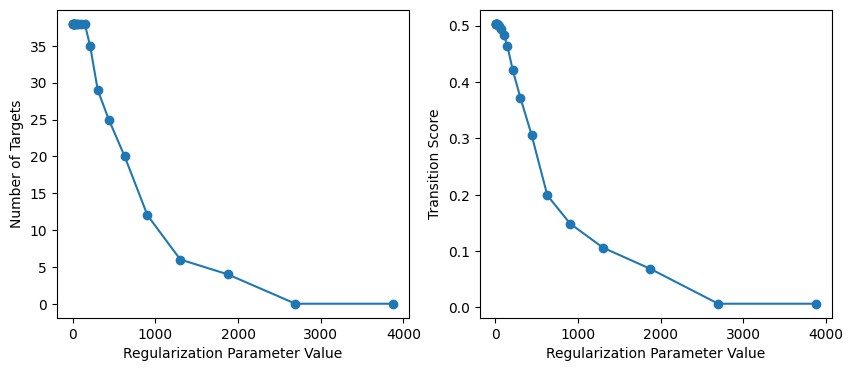

In [11]:
plot_df = solutions_reg_processed.sort_values(by='Lambda')
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(plot_df['Lambda'], plot_df['# of intervention targets'], marker='o')
axs[0].set_ylabel('Number of Targets')
axs[0].set_xlabel('Regularization Parameter Value')
axs[1].plot(plot_df['Lambda'], plot_df['TransProp'], marker='o')
axs[1].set_ylabel('Transition Score')
axs[1].set_xlabel('Regularization Parameter Value')
#plt.savefig(f'{savedir}/reg_top_{len(top_nodes)}_nodes.png')
#plt.close()

In [2]:
solutions_reg = pd.read_csv("solutions_reg.csv")
solutions_reg_processed = pd.read_csv("solutions_reg_processed.csv")

In [5]:
  plot_df = solutions_reg_processed.sort_values(by='Lambda')                                                                                                                     
  plot_df = plot_df.drop_duplicates(subset='# of intervention targets', keep='first')                                                                                            
  plot_df = plot_df[plot_df['# of intervention targets'] > 0]                                                                                                                    
                                                                                                                                                                                 
  fig, ax = plt.subplots(figsize=(6, 4))                                                                                                                                         
  ax.plot(plot_df['Lambda'], plot_df['# of intervention targets'], marker='o')                                                                                                   
  ax.set_ylabel('Number of Intervention Targets')                                                                                                                                             
  ax.set_xlabel('Regularization Value ($\lambda$)')
  plt.title('COAST solutions by regularization approach\n on the real scRNA-seq dataset')
  plt.tight_layout()                                                                                                                                
  plt.savefig(f'solutions_reg_chen.png', dpi=300)
  plt.close()

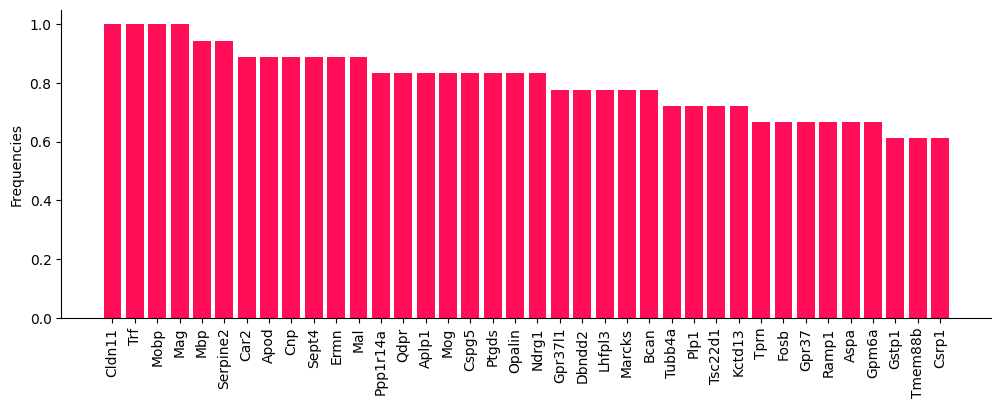

In [3]:
# Example Usage
freqs, intv_vals = visualize_reg(solutions_reg, solutions_reg_processed, thres_val=0.1)
freqs = sort_nodes(freqs)
dowhy_plot.bar_plot(freqs, ylabel='Frequencies', figure_size=(12,4))
#sns.heatmap(intv_vals, cmap='coolwarm', center=0)

## Post-intervention analysis

### Get the nodes that change significantly following interventions

In [23]:
### By the results of the regularization approach
max_interventions = 38
optimal_solutions_reg = solutions_reg_processed[solutions_reg_processed['# of intervention targets'] <= max_interventions]
optimal_solutions_reg.reset_index(drop=True, inplace=True)
intervened_nodes = optimal_solutions_reg['intervention targets'][0]
intervened_values = optimal_solutions_reg['intervention values'][0]

In [24]:
post_changes_df = causal_object.get_affected_nodes(intervened_nodes, intervened_values, test='parametric', alpha=0.05, thres_logFC=2)
post_changes_df

,Genes,Adj P-val,logFC
0,Slc12a2,0.000000e+00,2.794171
1,Bex2,0.000000e+00,-3.684178
2,Car2,0.000000e+00,8.088839
3,Ermn,0.000000e+00,7.816962
4,Mag,0.000000e+00,8.083131
5,Qdpr,0.000000e+00,7.262353
6,Lhfpl3,0.000000e+00,-7.877596
7,Gstp1,0.000000e+00,3.945089
8,Opalin,0.000000e+00,6.196702
9,Mog,0.000000e+00,8.526850


In [25]:
post_changes_df.to_csv("post_changes_pert38.csv", index=False)

In [30]:
### By the results of the regularization approach
max_interventions = 29
optimal_solutions_reg = solutions_reg_processed[solutions_reg_processed['# of intervention targets'] <= max_interventions]
optimal_solutions_reg.reset_index(drop=True, inplace=True)
intervened_nodes = optimal_solutions_reg['intervention targets'][0]
intervened_values = optimal_solutions_reg['intervention values'][0]

In [31]:
post_changes_df = causal_object.get_affected_nodes(intervened_nodes, intervened_values, test='parametric', alpha=0.05, thres_logFC=2)
post_changes_df

,Genes,Adj P-val,logFC
0,Slc12a2,0.000000e+00,2.343995
1,Cldn11,0.000000e+00,9.062376
2,Ndrg1,0.000000e+00,2.687301
3,Dbndd2,0.000000e+00,4.356418
4,Serpine2,0.000000e+00,-7.560897
5,Mog,0.000000e+00,5.350067
6,Opalin,0.000000e+00,2.159493
7,Lhfpl3,0.000000e+00,-4.740841
8,Qdpr,0.000000e+00,4.281964
9,Mag,0.000000e+00,8.075268


In [32]:
post_changes_df.to_csv("post_changes_pert29.csv", index=False)

In [37]:
### By the results of the regularization approach
max_interventions = 20
optimal_solutions_reg = solutions_reg_processed[solutions_reg_processed['# of intervention targets'] <= max_interventions]
optimal_solutions_reg.reset_index(drop=True, inplace=True)
intervened_nodes = optimal_solutions_reg['intervention targets'][0]
intervened_values = optimal_solutions_reg['intervention values'][0]

In [38]:
post_changes_df = causal_object.get_affected_nodes(intervened_nodes, intervened_values, test='parametric', alpha=0.05, thres_logFC=2)
post_changes_df

,Genes,Adj P-val,logFC
0,Mobp,0.000000e+00,5.385008
1,Apod,0.000000e+00,3.724100
2,Mbp,0.000000e+00,4.107292
3,Car2,0.000000e+00,4.237338
4,Mag,0.000000e+00,7.572880
5,Serpine2,0.000000e+00,-5.237807
6,Cldn11,0.000000e+00,10.104172
7,Trf,0.000000e+00,7.877595
8,Cnp,1.936316e-310,3.136064
9,Ugt8a,1.068177e-182,2.151253


In [39]:
post_changes_df.to_csv("post_changes_pert20.csv", index=False)

In [63]:
### By the results of the regularization approach
max_interventions = 12
optimal_solutions_reg = solutions_reg_processed[solutions_reg_processed['# of intervention targets'] <= max_interventions]
optimal_solutions_reg.reset_index(drop=True, inplace=True)
intervened_nodes = optimal_solutions_reg['intervention targets'][0]
intervened_values = optimal_solutions_reg['intervention values'][0]

In [64]:
post_changes_df = causal_object.get_affected_nodes(intervened_nodes, intervened_values, test='parametric', alpha=0.05, thres_logFC=1)
post_changes_df

,Genes,Adj P-val,logFC
0,Trf,0.000000e+00,7.011015
1,Cldn11,0.000000e+00,9.850770
2,Mobp,0.000000e+00,4.405445
3,Serpine2,0.000000e+00,-3.750742
4,Mag,0.000000e+00,6.438436
5,Car2,0.000000e+00,2.751036
6,Mbp,7.361270e-295,3.076184
7,Ermn,1.521898e-271,1.119399
8,Apod,1.405441e-230,1.673859
9,Sept4,3.429403e-173,1.633474


In [56]:
post_changes_df.to_csv("post_changes_pert12.csv", index=False)

In [76]:
### By the results of the regularization approach
max_interventions = 6
optimal_solutions_reg = solutions_reg_processed[solutions_reg_processed['# of intervention targets'] <= max_interventions]
optimal_solutions_reg.reset_index(drop=True, inplace=True)
intervened_nodes = optimal_solutions_reg['intervention targets'][0]
intervened_values = optimal_solutions_reg['intervention values'][0]

In [77]:
post_changes_df = causal_object.get_affected_nodes(intervened_nodes, intervened_values, test='parametric', alpha=0.05, thres_logFC=1)
post_changes_df

,Genes,Adj P-val,logFC
0,Mobp,0.000000e+00,2.757308
1,Mag,0.000000e+00,4.935790
2,Serpine2,0.000000e+00,-2.069380
3,Cldn11,0.000000e+00,9.488243
4,Trf,0.000000e+00,5.892981
5,Sept4,3.971581e-140,1.453446
6,Mbp,1.080723e-57,1.249821
7,Ugt8a,7.550759e-44,1.000577


In [59]:
post_changes_df.to_csv("post_changes_pert6.csv", index=False)

In [82]:
### By the results of the regularization approach
max_interventions = 4
optimal_solutions_reg = solutions_reg_processed[solutions_reg_processed['# of intervention targets'] <= max_interventions]
optimal_solutions_reg.reset_index(drop=True, inplace=True)
intervened_nodes = optimal_solutions_reg['intervention targets'][0]
intervened_values = optimal_solutions_reg['intervention values'][0]

In [83]:
post_changes_df = causal_object.get_affected_nodes(intervened_nodes, intervened_values, test='parametric', alpha=0.05, thres_logFC=1)
post_changes_df

,Genes,Adj P-val,logFC
0,Mag,0.000000e+00,2.465712
1,Cldn11,0.000000e+00,8.592354
2,Trf,0.000000e+00,4.144720
3,Sept4,1.243114e-116,1.316210


In [62]:
post_changes_df.to_csv("post_changes_pert4.csv", index=False)

### Pathway analysis

In [84]:
gene_names = list(post_changes_df['Genes'])

In [27]:
### Approach 2 (gProfiler):
gprofiler_results = gprofiler_analysis(gene_names, organism='mmusculus')
print(gprofiler_results.head())

  source      native                        name       p_value  significant  \
0  GO:BP  GO:0010001  glial cell differentiation  1.667697e-13         True   
1  GO:BP  GO:0042063                 gliogenesis  4.422364e-13         True   
2  GO:CC  GO:0043209               myelin sheath  6.768401e-13         True   
3  GO:BP  GO:0007272     ensheathment of neurons  7.770621e-11         True   
4  GO:BP  GO:0008366           axon ensheathment  7.770621e-11         True   

                                         description  term_size  query_size  \
0  "The process in which a relatively unspecializ...        286          48   
1  "The process that results in the generation of...        392          48   
2  "An electrically insulating fatty layer that s...        203          50   
3  "The process in which glial cells envelop neur...        191          48   
4  "Any process in which the axon of a neuron is ...        191          48   

   intersection_size  effective_domain_size  preci

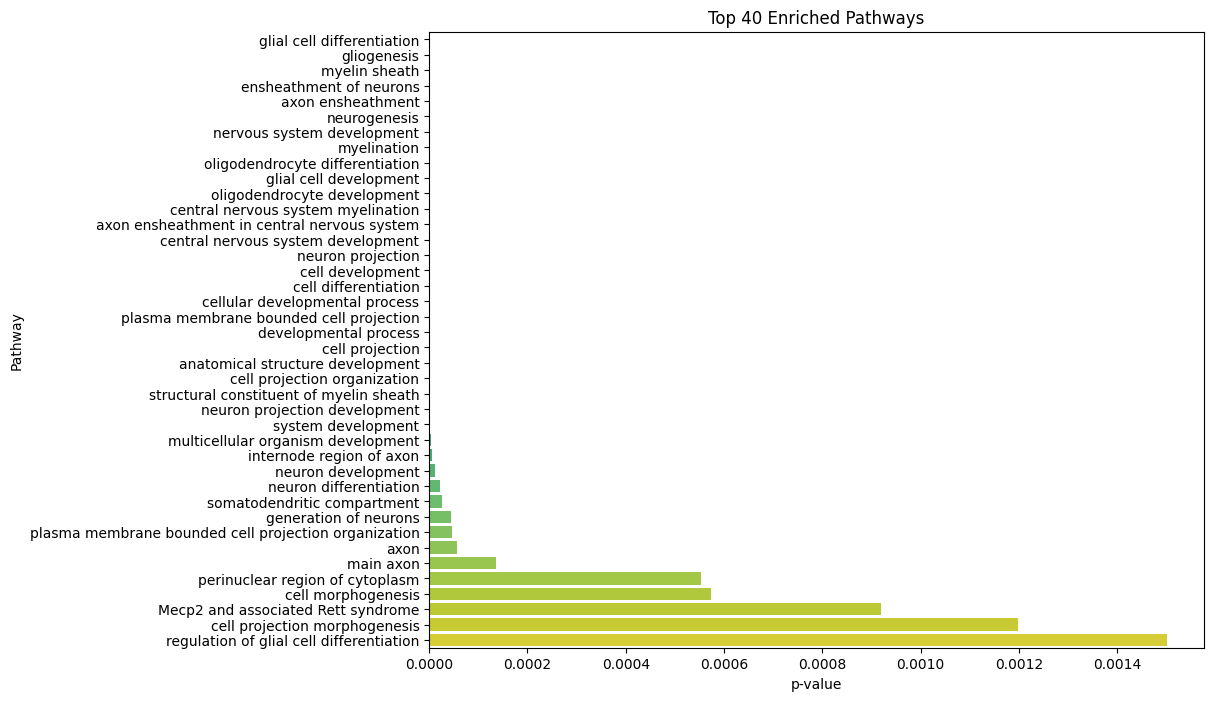

In [28]:
plt.figure(figsize=(10, 8))
sns.barplot(x='p_value', y='name', data=gprofiler_results.head(40), palette='viridis')
plt.xlabel('p-value')
plt.ylabel('Pathway')
plt.title('Top 40 Enriched Pathways')
#plt.savefig('enriched_pathways_gprofiler.png')
plt.show()

In [29]:
gprofiler_results.to_csv("gprofiler_res_pert38.csv", index=False)

In [34]:
### Approach 2 (gProfiler):
gprofiler_results = gprofiler_analysis(gene_names, organism='mmusculus')
print(gprofiler_results.head())

  source      native                        name       p_value  significant  \
0  GO:BP  GO:0042063                 gliogenesis  1.421243e-11         True   
1  GO:BP  GO:0010001  glial cell differentiation  1.914647e-11         True   
2  GO:CC  GO:0043209               myelin sheath  4.007779e-10         True   
3  GO:BP  GO:0008366           axon ensheathment  1.149018e-09         True   
4  GO:BP  GO:0007272     ensheathment of neurons  1.149018e-09         True   

                                         description  term_size  query_size  \
0  "The process that results in the generation of...        392          30   
1  "The process in which a relatively unspecializ...        286          30   
2  "An electrically insulating fatty layer that s...        203          32   
3  "Any process in which the axon of a neuron is ...        191          30   
4  "The process in which glial cells envelop neur...        191          30   

   intersection_size  effective_domain_size  preci

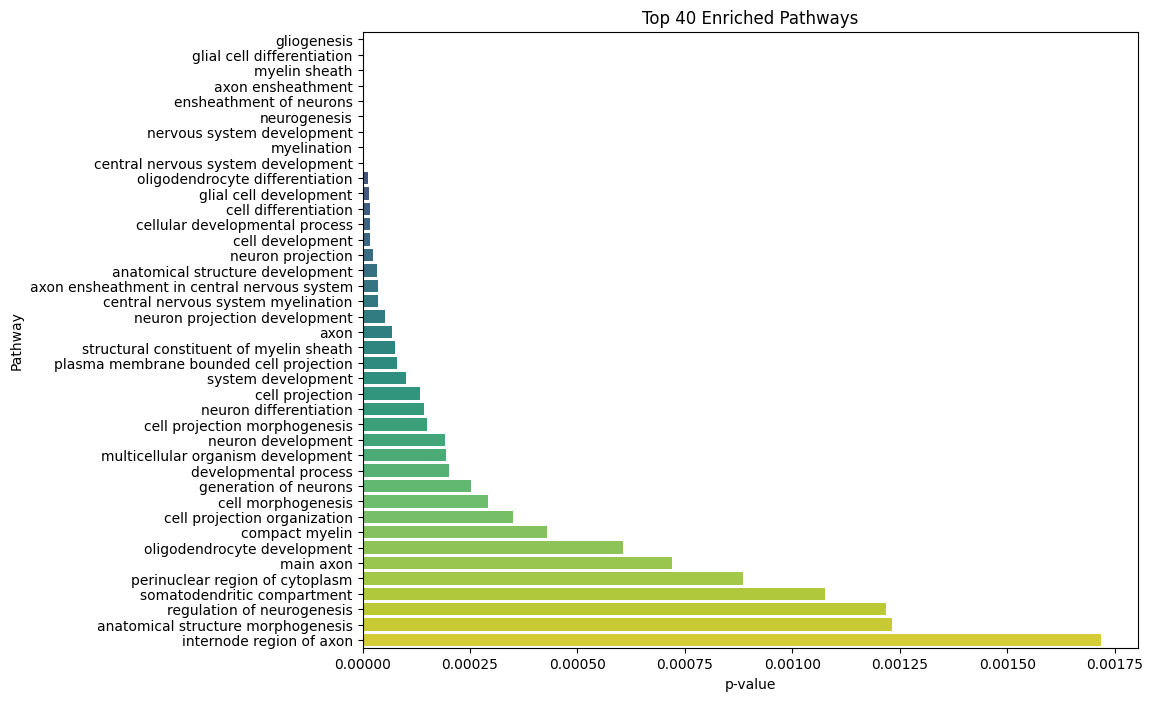

In [35]:
plt.figure(figsize=(10, 8))
sns.barplot(x='p_value', y='name', data=gprofiler_results.head(40), palette='viridis')
plt.xlabel('p-value')
plt.ylabel('Pathway')
plt.title('Top 40 Enriched Pathways')
#plt.savefig('enriched_pathways_gprofiler.png')
plt.show()

In [36]:
gprofiler_results.to_csv("gprofiler_res_pert29.csv", index=False)

In [41]:
### Approach 2 (gProfiler):
gprofiler_results = gprofiler_analysis(gene_names, organism='mmusculus')
print(gprofiler_results.head())

  source      native                        name       p_value  significant  \
0  GO:CC  GO:0043209               myelin sheath  1.068224e-08         True   
1  GO:BP  GO:0008366           axon ensheathment  7.228222e-08         True   
2  GO:BP  GO:0007272     ensheathment of neurons  7.228222e-08         True   
3  GO:BP  GO:0042552                 myelination  9.248183e-06         True   
4  GO:BP  GO:0007399  nervous system development  4.930911e-05         True   

                                         description  term_size  query_size  \
0  "An electrically insulating fatty layer that s...        203          11   
1  "Any process in which the axon of a neuron is ...        191          11   
2  "The process in which glial cells envelop neur...        191          11   
3  "The process in which myelin sheaths are forme...        188          11   
4  "The process whose specific outcome is the pro...       2593          11   

   intersection_size  effective_domain_size  preci

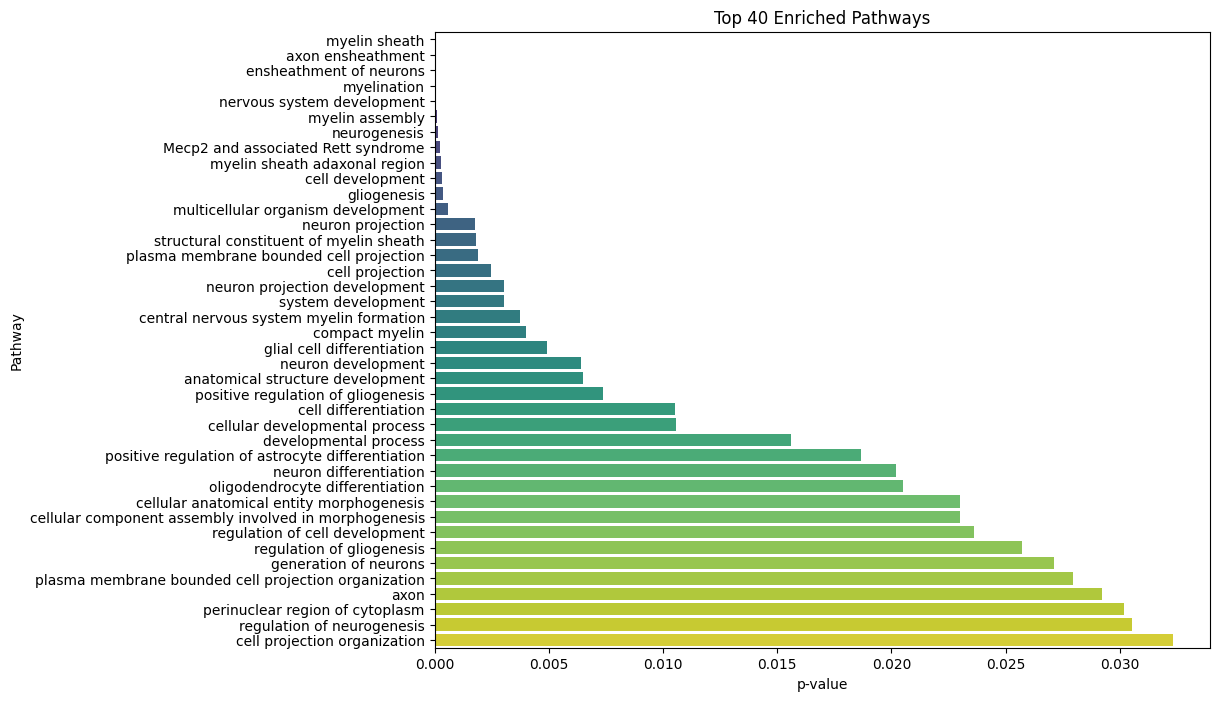

In [42]:
plt.figure(figsize=(10, 8))
sns.barplot(x='p_value', y='name', data=gprofiler_results.head(40), palette='viridis')
plt.xlabel('p-value')
plt.ylabel('Pathway')
plt.title('Top 40 Enriched Pathways')
#plt.savefig('enriched_pathways_gprofiler.png')
plt.show()

In [43]:
gprofiler_results.to_csv("gprofiler_res_pert20.csv", index=False)

In [66]:
### Approach 2 (gProfiler):
gprofiler_results = gprofiler_analysis(gene_names, organism='mmusculus')
print(gprofiler_results.head())

  source      native                     name       p_value  significant  \
0  GO:CC  GO:0043209            myelin sheath  3.558198e-09         True   
1  GO:BP  GO:0007272  ensheathment of neurons  2.617793e-08         True   
2  GO:BP  GO:0008366        axon ensheathment  2.617793e-08         True   
3  GO:CC  GO:0043005        neuron projection  8.424557e-07         True   
4  GO:BP  GO:0042552              myelination  2.109618e-06         True   

                                         description  term_size  query_size  \
0  "An electrically insulating fatty layer that s...        203          17   
1  "The process in which glial cells envelop neur...        191          17   
2  "Any process in which the axon of a neuron is ...        191          17   
3  "A prolongation or process extending from a ne...       1544          17   
4  "The process in which myelin sheaths are forme...        188          17   

   intersection_size  effective_domain_size  precision    recall    

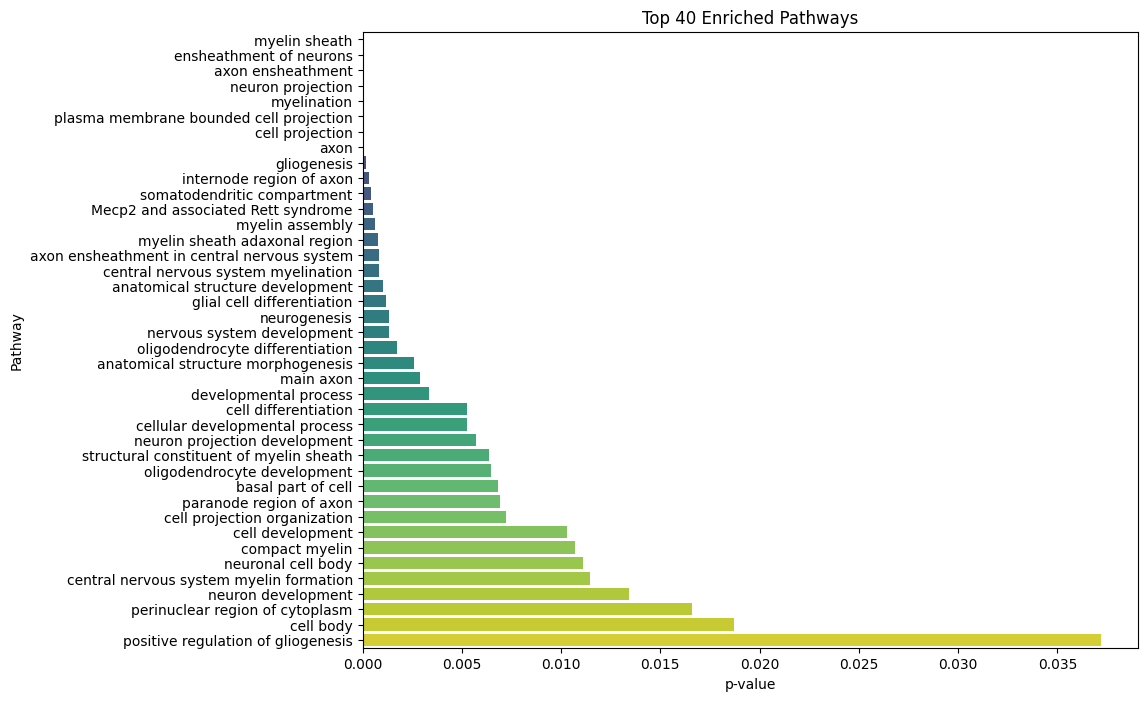

In [67]:
plt.figure(figsize=(10, 8))
sns.barplot(x='p_value', y='name', data=gprofiler_results.head(40), palette='viridis')
plt.xlabel('p-value')
plt.ylabel('Pathway')
plt.title('Top 40 Enriched Pathways')
#plt.savefig('enriched_pathways_gprofiler.png')
plt.show()

In [68]:
gprofiler_results.to_csv("gprofiler_res_pert12.csv", index=False)

In [79]:
### Approach 2 (gProfiler):
gprofiler_results = gprofiler_analysis(gene_names, organism='mmusculus')
print(gprofiler_results.head())

  source      native                     name       p_value  significant  \
0  GO:BP  GO:0007272  ensheathment of neurons  9.058078e-10         True   
1  GO:BP  GO:0008366        axon ensheathment  9.058078e-10         True   
2  GO:BP  GO:0042552              myelination  3.473520e-07         True   
3  GO:BP  GO:0032288          myelin assembly  2.139279e-05         True   
4  GO:CC  GO:0043209            myelin sheath  2.241138e-05         True   

                                         description  term_size  query_size  \
0  "The process in which glial cells envelop neur...        191           7   
1  "Any process in which the axon of a neuron is ...        191           7   
2  "The process in which myelin sheaths are forme...        188           7   
3  "The process in which the wraps of cell membra...         24           7   
4  "An electrically insulating fatty layer that s...        203           7   

   intersection_size  effective_domain_size  precision    recall    

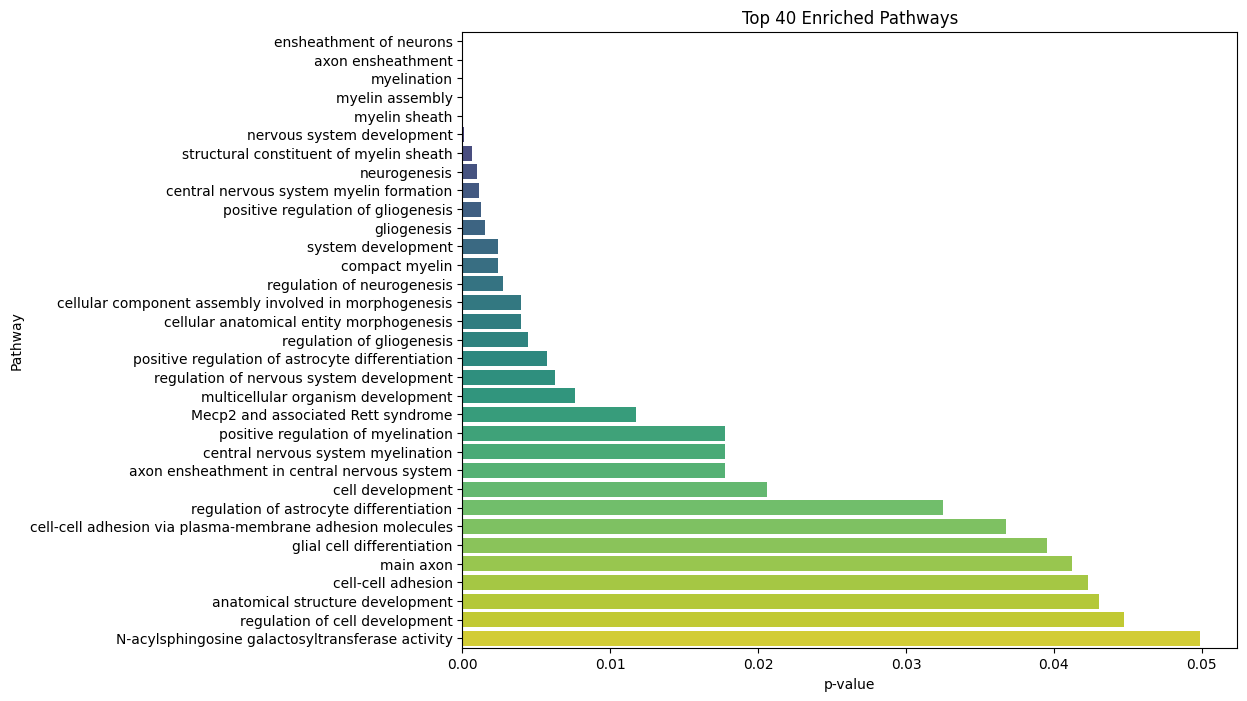

In [80]:
plt.figure(figsize=(10, 8))
sns.barplot(x='p_value', y='name', data=gprofiler_results.head(40), palette='viridis')
plt.xlabel('p-value')
plt.ylabel('Pathway')
plt.title('Top 40 Enriched Pathways')
#plt.savefig('enriched_pathways_gprofiler.png')
plt.show()

In [81]:
gprofiler_results.to_csv("gprofiler_res_pert6.csv", index=False)

In [85]:
### Approach 2 (gProfiler):
gprofiler_results = gprofiler_analysis(gene_names, organism='mmusculus')
print(gprofiler_results.head())

  source      native                                           name   p_value  \
0  GO:BP  GO:0007272                        ensheathment of neurons  0.000173   
1  GO:BP  GO:0008366                              axon ensheathment  0.000173   
2  GO:BP  GO:0031643             positive regulation of myelination  0.001274   
3  GO:BP  GO:0031646  positive regulation of nervous system process  0.004606   
4  GO:BP  GO:0031641                      regulation of myelination  0.007403   

   significant                                        description  term_size  \
0         True  "The process in which glial cells envelop neur...        191   
1         True  "Any process in which the axon of a neuron is ...        191   
2         True  "Any process that activates or increases the f...         26   
3         True  "Any process that activates or increases the f...         49   
4         True  "Any process that modulates the frequency, rat...         62   

   query_size  intersection_size

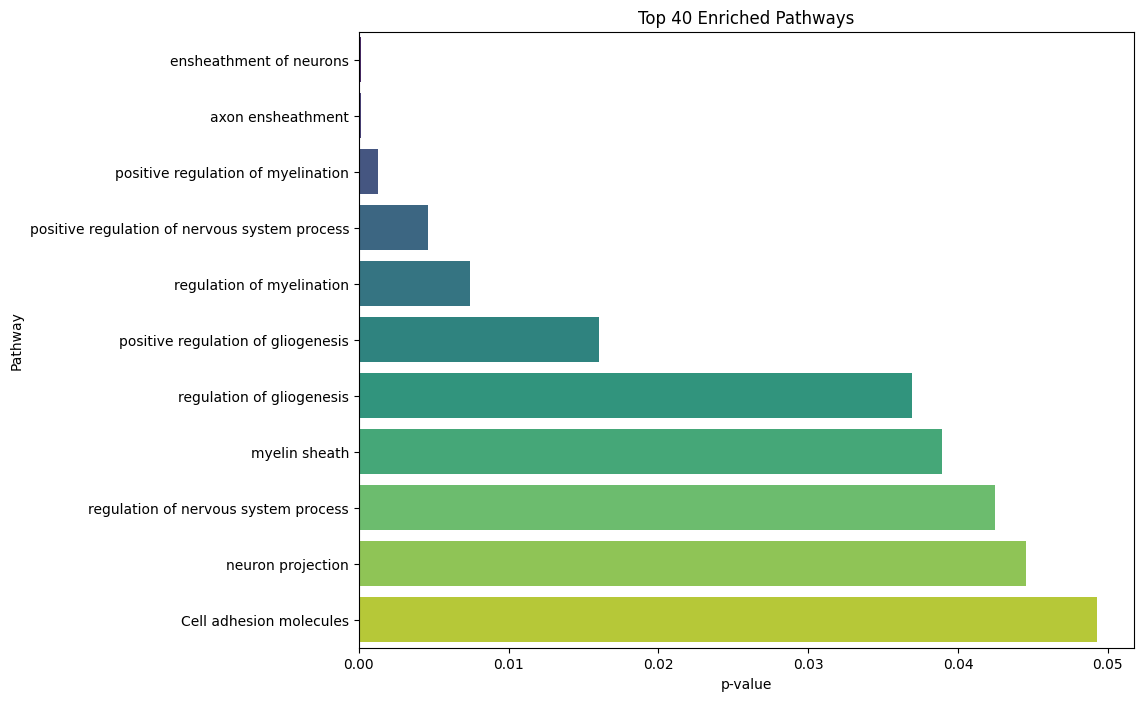

In [86]:
plt.figure(figsize=(10, 8))
sns.barplot(x='p_value', y='name', data=gprofiler_results.head(40), palette='viridis')
plt.xlabel('p-value')
plt.ylabel('Pathway')
plt.title('Top 40 Enriched Pathways')
#plt.savefig('enriched_pathways_gprofiler.png')
plt.show()

In [87]:
gprofiler_results.to_csv("gprofiler_res_pert4.csv", index=False)

## Compare with DE

In [44]:
with open("../targets.txt") as f:
    targets = [line.strip() for line in f if line.strip()]

In [93]:
comb_list = []
for n in [20,6]:
    for seed in [10,88,100,888,1000]:
        random.seed(seed)  # any fixed integer for reproducibility                                                                          
        sampled = random.sample(targets, n)
        comb_list.append(sampled)

In [94]:
solutions_DE = get_perturbation_targets_by_specified_combs_parallel_standalone(causal_object, combs = comb_list, minval=-5000, maxval=5000, maxiter=10000, minimize_target_state_change=False, gamma=1e-2)
solutions_DE.to_csv('{}/solutions_DE_random_20_and_6.csv'.format(savedir), index=False)

Using 16 workers for parallel optimization


[Parallel(n_jobs=16)]: Using backend LokyBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  10 out of  10 | elapsed:   50.7s finished


Successfully optimized 10/10 combinations


In [95]:
solutions_DE

,intervention targets,intervention values,Diff,TransProp,# of intervention targets
0,"[Cdc37l1, Dbndd2, Limch1, 4732418C07Rik, Bcan,...","[2.4077306851594584, 7.723162752341563, 2.5463...",3665.065207,0.100948,20
1,"[Gria2, Srrm2, Fez1, Lpar1, Limch1, Kif1b, Sfr...","[-5.214233548587085, -2.1832609803317036, 2.47...",3717.787280,0.088015,20
2,"[Osbpl1a, Cdc37l1, Marcksl1, Pigz, Ttll7, Ttc3...","[3.752488684707533, 2.407732553065895, -2.3513...",3736.387551,0.083453,20
3,"[Epn2, Klf6, S100b, Lgi3, Pigz, Pip4k2a, Mettl...","[-2.7224983333965964, -3.9120337965686494, -3....",3828.014505,0.060976,20
4,"[Car14, Sfrs18, Ndrg2, Hip1, Arl2bp, Ttyh1, Ub...","[3.645906634870076, -2.3342381624253754, -2.51...",3837.988229,0.058530,20
5,"[Cdc37l1, Dbndd2, Limch1, 4732418C07Rik, Bcan,...","[2.4077439485034255, 7.723206204571894, 2.5463...",3938.653810,0.033836,6
6,"[Epn2, Klf6, S100b, Lgi3, Pigz, Pip4k2a]","[-2.7224953382613863, -3.912037090376153, -3.5...",4003.428162,0.017947,6
7,"[Gria2, Srrm2, Fez1, Lpar1, Limch1, Kif1b]","[-5.214236843275782, -2.183259499033084, 2.477...",4006.169541,0.017274,6
8,"[Osbpl1a, Cdc37l1, Marcksl1, Pigz, Ttll7, Ttc3]","[3.7525007953338596, 2.4077290463643877, -2.35...",4021.339185,0.013553,6
9,"[Car14, Sfrs18, Ndrg2, Hip1, Arl2bp, Ttyh1]","[3.645890491556379, -2.334244548675258, -2.511...",4029.220028,0.011620,6


In [96]:
  from scipy.stats import chi2                                                                                                                                                                                                                                                 
                                                                                                                                                        
  # ============================================================                                                                                        
  # Fisher's method to combine p-values across runs                                                                                                     
  # ============================================================                                                                                        
  def combine_pvalues_fisher(pvalues):                                                                                                                  
      """                                                                                                                                               
      Combine p-values using Fisher's method.                                                                                                           
      chi2_stat = -2 * sum(ln(p_i))                                                                                                                     
      df = 2 * k (where k = number of p-values)                                                                                                         
      Returns the combined p-value from the chi-squared distribution.                                                                                   
      """                                                                                                                                               
      pvalues = np.array(pvalues, dtype=float)                                                                                                          
      # Clip tiny p-values to avoid -inf in log                                                                                                         
      pvalues = np.clip(pvalues, 1e-300, 1.0)                                                                                                           
      k = len(pvalues)                                                                                                                                  
      chi2_stat = -2.0 * np.sum(np.log(pvalues))                                                                                                        
      combined_p = chi2.sf(chi2_stat, df=2 * k)                                                                                                         
      return combined_p                                                                                                                                 
                                                                                                                                                        
                                                                                                                                                        
  def combine_gprofiler_runs(gprofiler_list):                                                                                                           
      """                                                                                                                                               
      Given a list of gprofiler result DataFrames (one per seed),
      take the union of GO terms. For terms appearing in multiple runs,                                                                                 
      combine p-values via Fisher's method.                                                                                                             
                                                                                                                                                        
      Returns a single DataFrame with combined results, sorted by combined p-value.                                                                     
      """                                                                                                                                               
      # Collect all terms across runs, keyed by 'native' (GO ID)                                                                                        
      term_pvalues = {}   # native -> list of p_values                                                                                                  
      term_info = {}      # native -> dict of metadata (from first occurrence)                                                                          
                                                                                                                                                        
      for df in gprofiler_list:                                                                                                                         
          if df is None or df.empty:                                                                                                                    
              continue                                                                                                                                  
          for _, row in df.iterrows():                                                                                                                  
              go_id = row['native']                                                                                                                     
              if go_id not in term_pvalues:                                                                                                             
                  term_pvalues[go_id] = []                                                                                                              
                  term_info[go_id] = {                                                                                                                  
                      'source': row['source'],                                                                                                          
                      'native': row['native'],                                                                                                          
                      'name': row['name'],                                                                                                              
                      'description': row.get('description', ''),                                                                                        
                      'term_size': row.get('term_size', np.nan),                                                                                        
                  }                                                                                                                                     
              term_pvalues[go_id].append(row['p_value'])                                                                                                
                                                                                                                                                        
      # Combine p-values using Fisher's method                                                                                                          
      rows = []                                                                                                                                         
      for go_id, pvals in term_pvalues.items():                                                                                                         
          info = term_info[go_id]                                                                                                                       
          combined_p = combine_pvalues_fisher(pvals)                                                                                                    
          rows.append({                                                                                                                                 
              'source': info['source'],                                                                                                                 
              'native': info['native'],                                                                                                                 
              'name': info['name'],                                                                                                                     
              'description': info['description'],                                                                                                       
              'term_size': info['term_size'],                                                                                                           
              'combined_p_value': combined_p,                                                                                                           
              'n_runs': len(pvals),                                                                                                                     
              'individual_p_values': pvals,                                                                                                             
          })                                                                                                                                            
                                                                                                                                                        
      result = pd.DataFrame(rows)                                                                                                                       
      result = result.sort_values('combined_p_value').reset_index(drop=True)
      return result                                                                                                                                     
                                                                                                                                                        
                                                                                                                                                        
  # ============================================================                                                                                        
  # Run gprofiler for all 5 seeds per group and combine
  # ============================================================                                                                                        
  # solutions_DE rows 0-4: n=20 (seeds 10,88,100,888,1000)
  # solutions_DE rows 5-9: n=6  (seeds 10,88,100,888,1000)                                                                                              
                                                                                                                                                        
  groups = {                                                                                                                                            
      'DE_random_20': {                                                                                                                                 
          'indices': [0, 1, 2, 3, 4],                                                                                                                   
          'thres_logFC': 2,                                                                                                                             
          'label': 'DE Random (20 targets)',                                                                                                            
      },                                                                                                                                                
      'DE_random_6': {                                                                                                                                  
          'indices': [5, 6, 7, 8, 9],                                                                                                                   
          'thres_logFC': 1,                                                                                                                             
          'label': 'DE Random (6 targets)',                                                                                                             
      },                                                                                                                                                
  }               
                                                                                                                                                        
  combined_results = {}                                                                                                                                 
                                                                                                                                                        
  for group_name, group_cfg in groups.items():                                                                                                          
      gprofiler_list = []
      for idx in group_cfg['indices']:                                                                                                                  
          intervened_nodes = solutions_DE['intervention targets'][idx]                                                                                  
          intervened_values = solutions_DE['intervention values'][idx]                                                                                  
          post_changes_df = causal_object.get_affected_nodes(                                                                                           
              intervened_nodes, intervened_values,                                                                                                      
              test='parametric', alpha=0.05,                                                                                                            
              thres_logFC=group_cfg['thres_logFC']                                                                                                      
          )                                                                                                                                             
          gene_names = list(post_changes_df['Genes'])                                                                                                   
          print(f"  {group_name} seed idx={idx}: {len(gene_names)} genes")                                                                              
          if len(gene_names) > 0:                                                                                                                       
              gp_res = gprofiler_analysis(gene_names, organism='mmusculus')                                                                             
              gprofiler_list.append(gp_res)                                                                                                             
          else:                                                                                                                                         
              gprofiler_list.append(pd.DataFrame())                                                                                                     
                                                                                                                                                        
      combined = combine_gprofiler_runs(gprofiler_list)                                                                                                 
      combined_results[group_name] = combined                                                                                                           
      combined.to_csv(f'gprofiler_res_{group_name}_combined.csv', index=False)                                                                          
      print(f"{group_name}: {len(combined)} total terms after union")                                                                                   


  DE_random_20 seed idx=0: 20 genes
  DE_random_20 seed idx=1: 21 genes
  DE_random_20 seed idx=2: 24 genes
  DE_random_20 seed idx=3: 20 genes
  DE_random_20 seed idx=4: 20 genes
DE_random_20: 12 total terms after union
  DE_random_6 seed idx=5: 6 genes
  DE_random_6 seed idx=6: 6 genes
  DE_random_6 seed idx=7: 6 genes
  DE_random_6 seed idx=8: 6 genes
  DE_random_6 seed idx=9: 6 genes
DE_random_6: 8 total terms after union


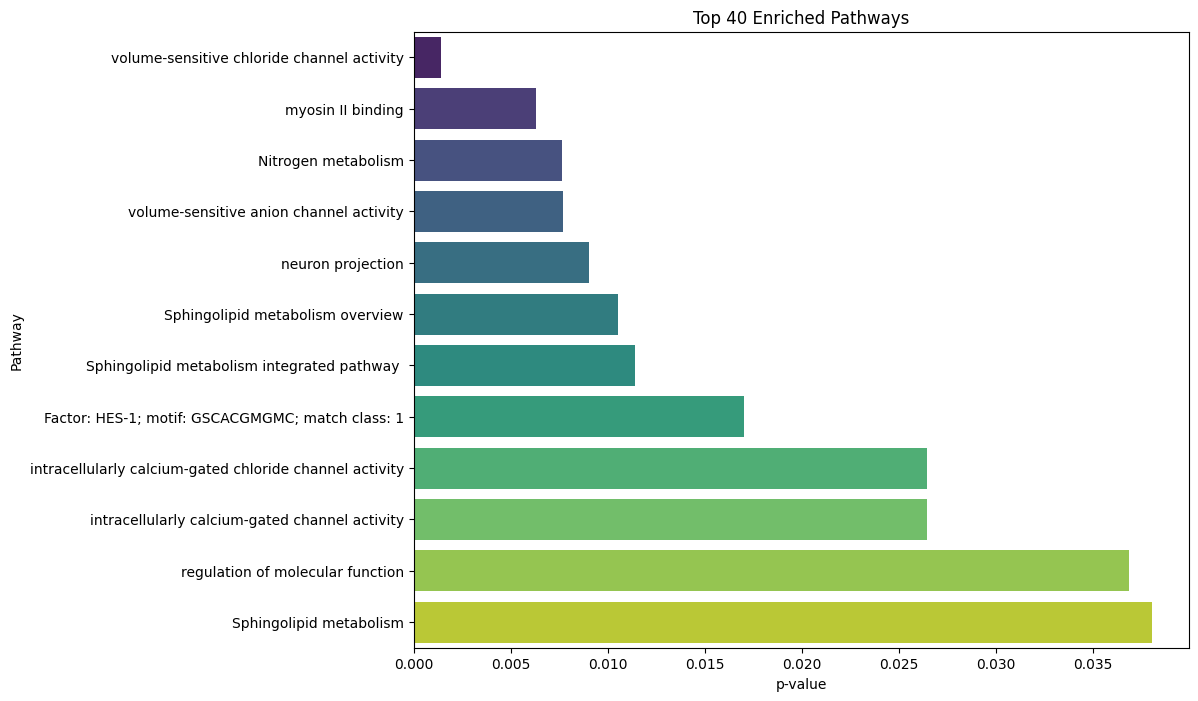

In [99]:
gprofiler_results = pd.read_csv("gprofiler_res_DE_random_20_combined.csv")
plt.figure(figsize=(10, 8))
sns.barplot(x='combined_p_value', y='name', data=gprofiler_results.head(40), palette='viridis')
plt.xlabel('p-value')
plt.ylabel('Pathway')
plt.title('Top 40 Enriched Pathways')
#plt.savefig('enriched_pathways_gprofiler.png')
plt.show()

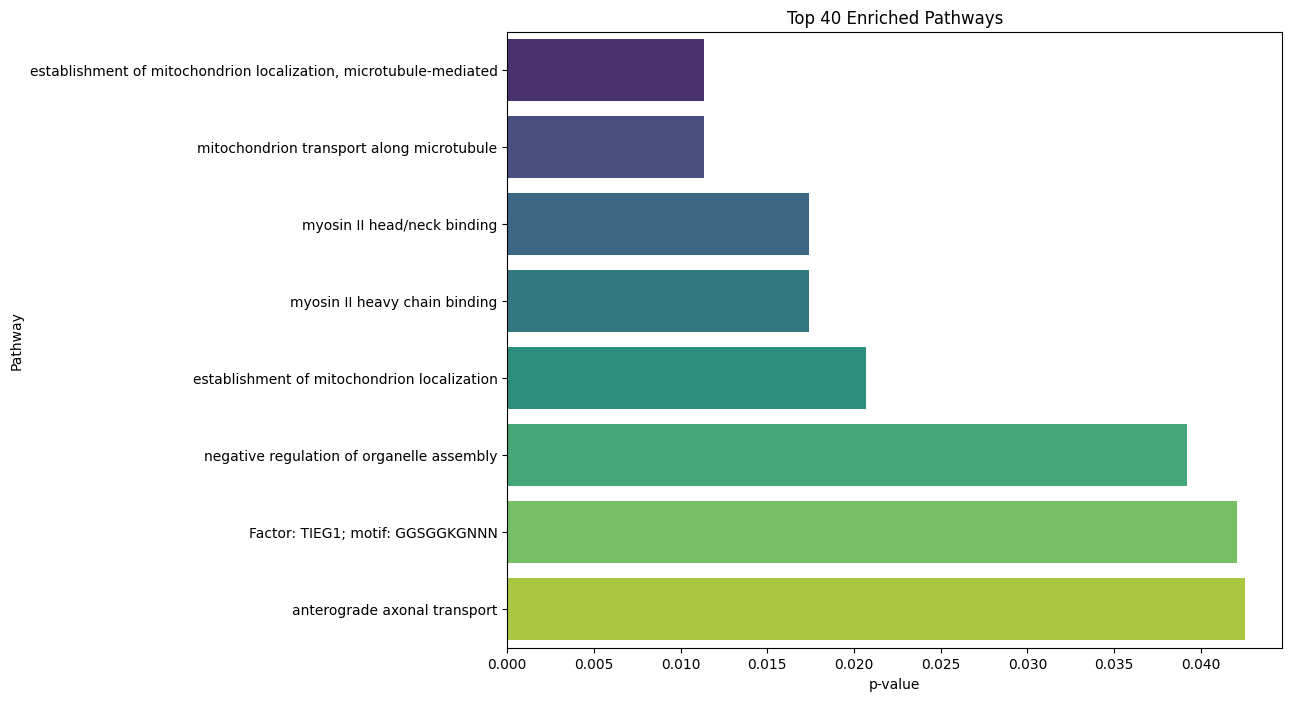

In [100]:
gprofiler_results = pd.read_csv("gprofiler_res_DE_random_6_combined.csv")
plt.figure(figsize=(10, 8))
sns.barplot(x='combined_p_value', y='name', data=gprofiler_results.head(40), palette='viridis')
plt.xlabel('p-value')
plt.ylabel('Pathway')
plt.title('Top 40 Enriched Pathways')
#plt.savefig('enriched_pathways_gprofiler.png')
plt.show()

## Visualization

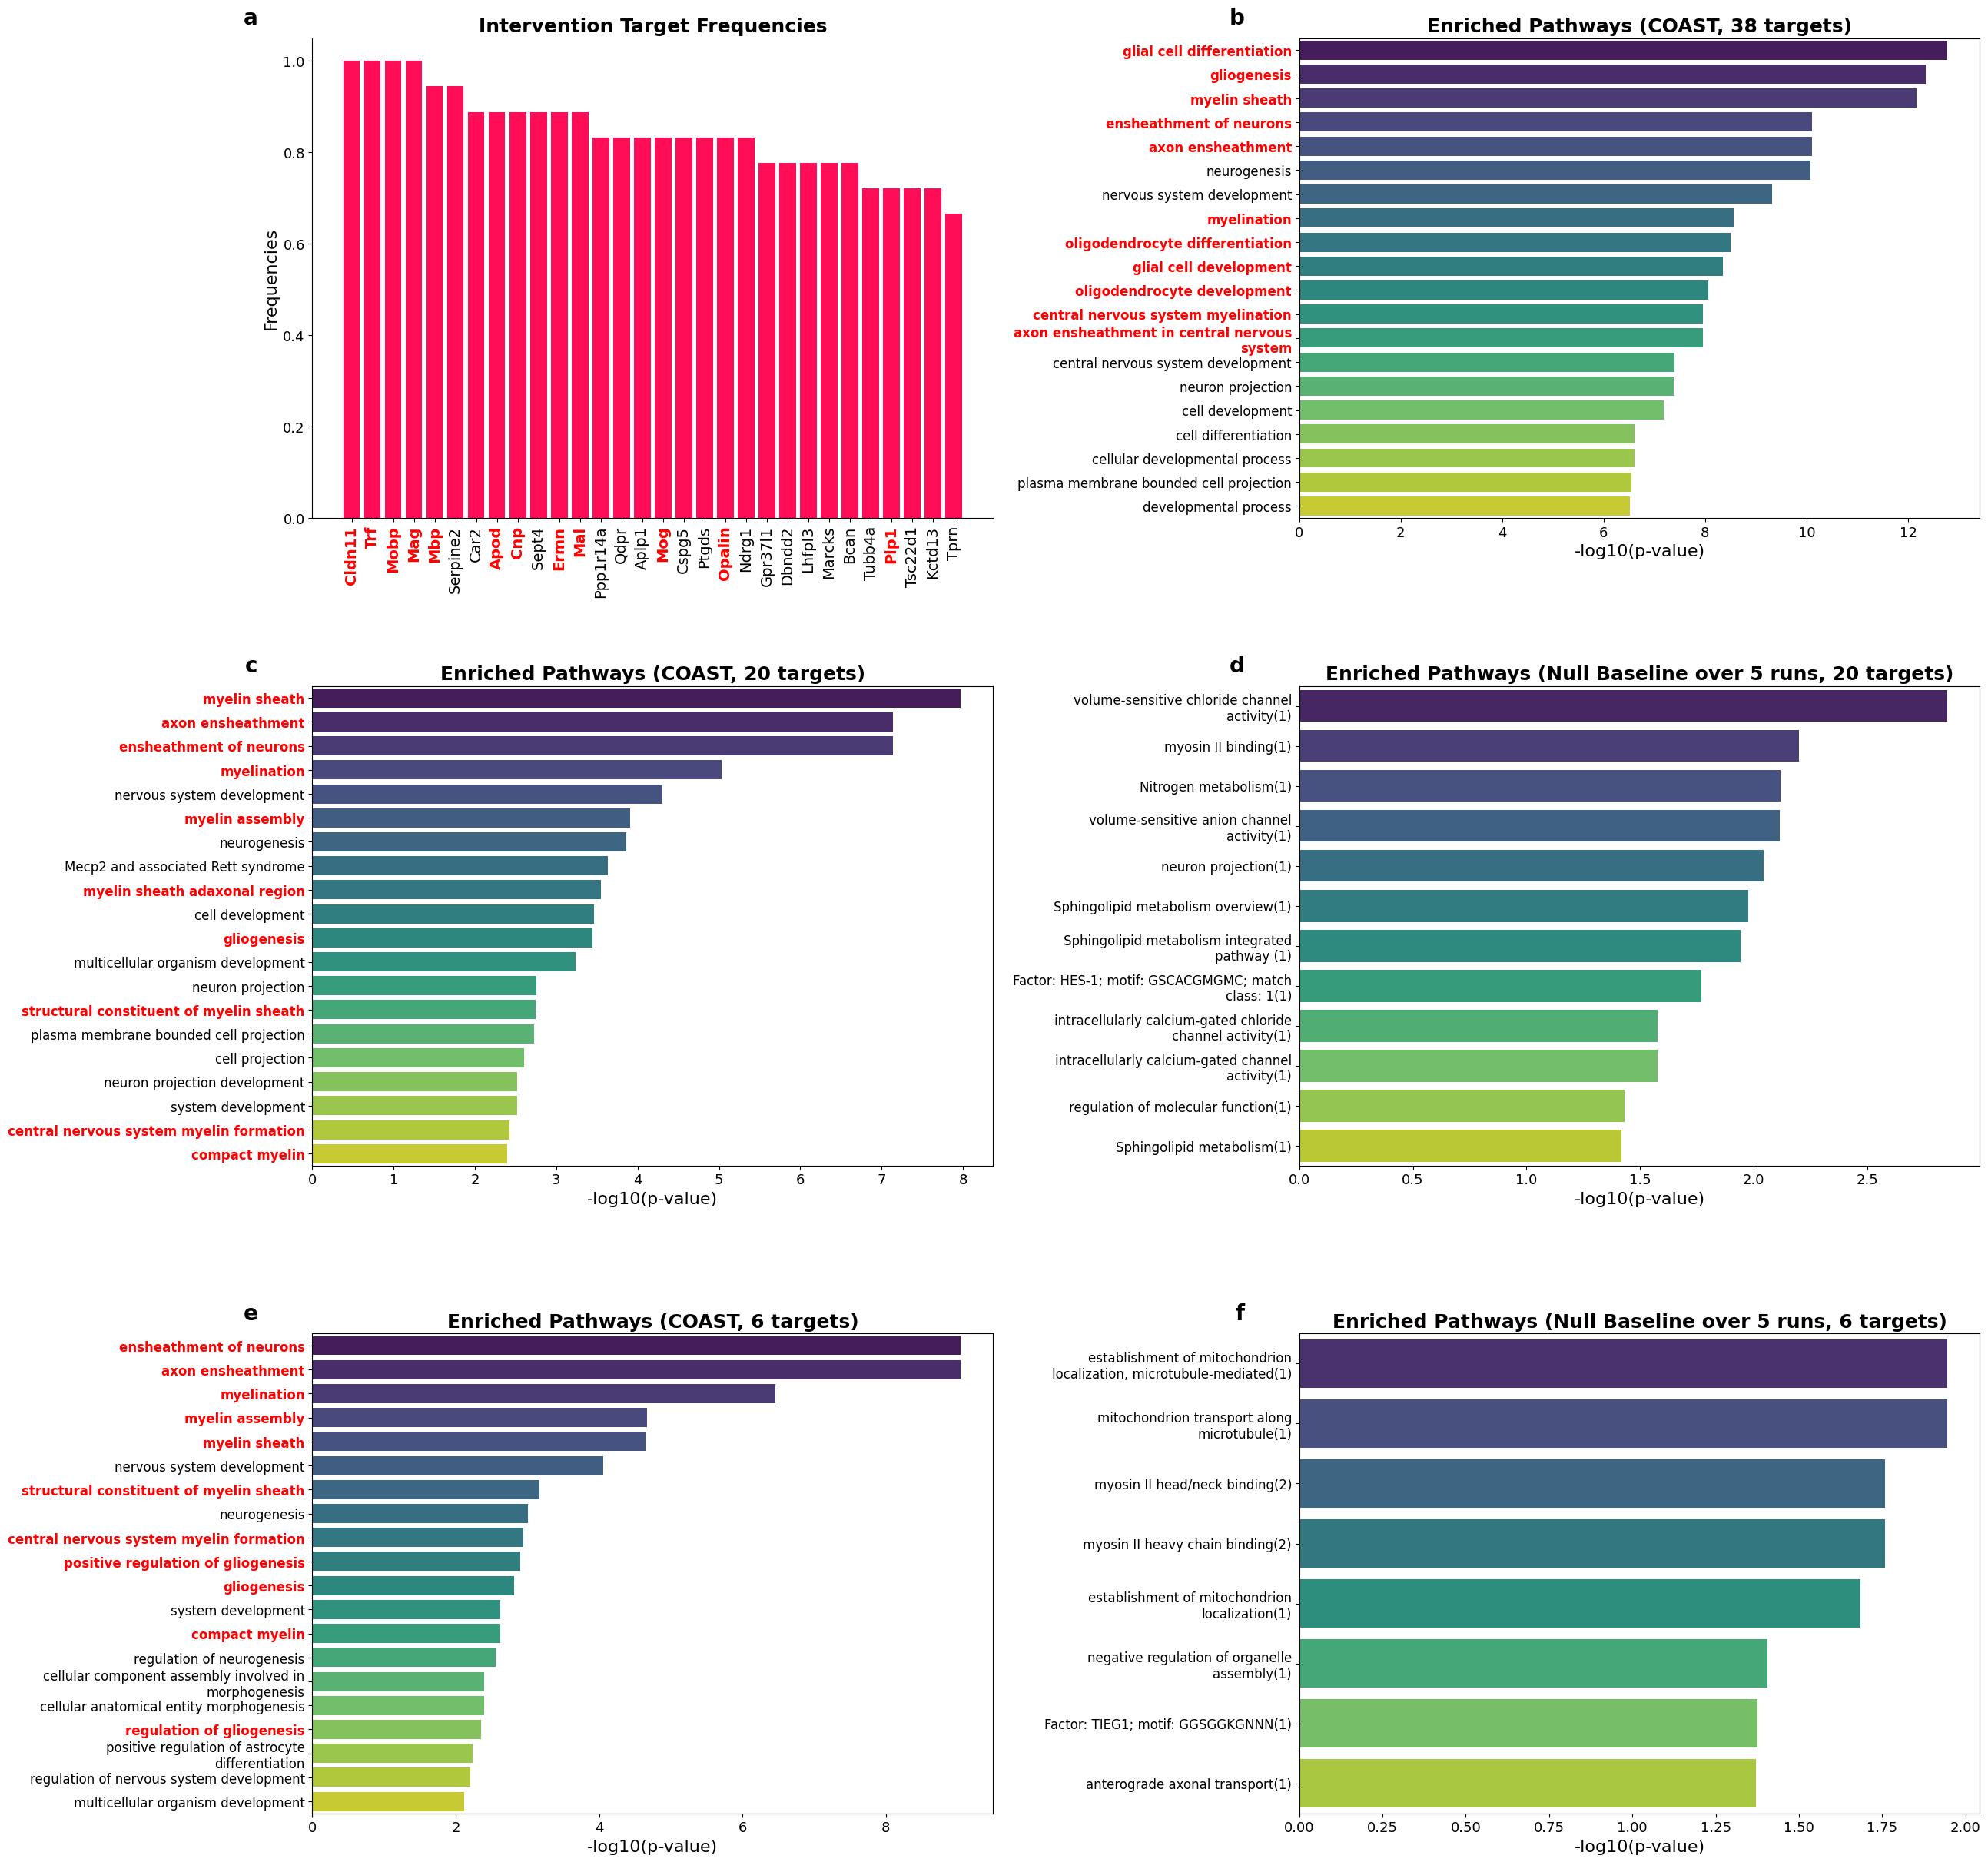

In [ ]:
# Combined plot: frequency bar plot + pathway visualizations
# Layout: 3 rows x 2 columns
# Row 1: (1) Frequency bar plot from visualize_reg, (2) Pathway pert38
# Row 2: (3) Pathway pert20, (4) Pathway DE20
# Row 3: (5) Pathway pert6, (6) Pathway DE6

import seaborn as sns
import textwrap

# --- Font size constants ---
TITLE_SIZE = 18
AXIS_LABEL_SIZE = 16
TICK_LABEL_SIZE = 13
GENE_TICK_SIZE = 14
PANEL_LABEL_SIZE = 20
PATHWAY_YTICK_SIZE = 12

# --- Genes to highlight in frequency bar plot ---
HIGHLIGHT_GENES = {'Cldn11', 'Trf', 'Mobp', 'Mag', 'Mal', 'Mog', 'Mbp', 'Plp1', 'Cnp', 'Apod', 'Ermn', 'Opalin'}

# --- Keywords for highlighting GO terms ---
HIGHLIGHT_KEYWORDS = ['myelin', 'sheath', 'ensheathment', 'myelination', 'oligodendrocyte', 'glial cell', 'gliogenesis']

# --- Subplot 1 data: frequencies from visualize_reg (top 30) ---
freqs, intv_vals = visualize_reg(solutions_reg, solutions_reg_processed, thres_val=0.1)
freqs = sort_nodes(freqs)
freqs = dict(list(freqs.items())[:30])

# --- Subplot 2-6 data: load pathway CSVs ---
pw_pert38 = pd.read_csv('gprofiler_res_pert38.csv')
pw_pert20 = pd.read_csv('gprofiler_res_pert20.csv')
pw_DE20 = pd.read_csv('gprofiler_res_DE_random_20_combined.csv')
pw_pert6 = pd.read_csv('gprofiler_res_pert6.csv')
pw_DE6 = pd.read_csv('gprofiler_res_DE_random_6_combined.csv')

pw_DE20['new_name'] = pw_DE20['name'] + '(' + pw_DE20['n_runs'].astype(str) + ')'
pw_DE6['new_name'] = pw_DE6['name'] + '(' + pw_DE6['n_runs'].astype(str) + ')'

# --- Create figure ---
fig, axes = plt.subplots(3, 2, figsize=(28, 30),
                         gridspec_kw={'hspace': 0.35, 'wspace': 0.45})

def wrap_label(text, width=40):
    return '\n'.join(textwrap.wrap(str(text), width=width))

def highlight_pathway_labels(ax):
    for label in ax.get_yticklabels():
        text_lower = label.get_text().lower()
        if any(kw in text_lower for kw in HIGHLIGHT_KEYWORDS):
            label.set_color('red')
            label.set_fontweight('bold')

# Helper to plot pathway enrichment on a given axis
def plot_pathway(ax, df, title, p_val_col_name, name_col_name, max_terms=20):
    if df.empty or len(df) == 0:
        ax.text(0.5, 0.5, 'No significant pathways', ha='center', va='center',
                fontsize=AXIS_LABEL_SIZE, transform=ax.transAxes)
        ax.set_title(title, fontsize=TITLE_SIZE, fontweight='bold')
        return
    plot_data = df.head(max_terms).copy()
    plot_data['-log10(p_value)'] = -np.log10(plot_data[p_val_col_name])
    plot_data['wrapped_name'] = plot_data[name_col_name].apply(wrap_label)
    sns.barplot(x='-log10(p_value)', y='wrapped_name', data=plot_data, palette='viridis', ax=ax)
    ax.set_xlabel('-log10(p-value)', fontsize=AXIS_LABEL_SIZE)
    ax.set_ylabel('')
    ax.set_title(title, fontsize=TITLE_SIZE, fontweight='bold')
    ax.tick_params(axis='y', labelsize=PATHWAY_YTICK_SIZE)
    ax.tick_params(axis='x', labelsize=TICK_LABEL_SIZE)
    highlight_pathway_labels(ax)

# --- Panel labels ---
panel_labels = ['a', 'b', 'c', 'd', 'e', 'f']
panel_positions = [(0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1)]

# --- Subplot 1 (a): Frequency bar plot (top 30) ---
ax1 = axes[0, 0]
ax1.bar(freqs.keys(), freqs.values(), color='#ff0d57', width=0.8)
ax1.set_ylabel('Frequencies', fontsize=AXIS_LABEL_SIZE)
ax1.set_title('Intervention Target Frequencies', fontsize=TITLE_SIZE, fontweight='bold')
ax1.tick_params(axis='x', rotation=90, labelsize=GENE_TICK_SIZE)
ax1.tick_params(axis='y', labelsize=TICK_LABEL_SIZE)
ax1.spines['right'].set_visible(False)
ax1.spines['top'].set_visible(False)
for label in ax1.get_xticklabels():
    if label.get_text() in HIGHLIGHT_GENES:
        label.set_color('red')
        label.set_fontweight('bold')

# --- Subplot 2 (b): Pathway pert38 ---
plot_pathway(axes[0, 1], pw_pert38, 'Enriched Pathways (COAST, 38 targets)', name_col_name='name', p_val_col_name='p_value')

# --- Subplot 3 (c): Pathway pert20 ---
plot_pathway(axes[1, 0], pw_pert20, 'Enriched Pathways (COAST, 20 targets)', name_col_name='name', p_val_col_name='p_value')

# --- Subplot 4 (d): Pathway MDA20 ---
plot_pathway(axes[1, 1], pw_DE20, 'Enriched Pathways (Null Baseline over 5 runs, 20 targets)', name_col_name='new_name', p_val_col_name='combined_p_value')

# --- Subplot 5 (e): Pathway pert6 ---
plot_pathway(axes[2, 0], pw_pert6, 'Enriched Pathways (COAST, 6 targets)', name_col_name='name', p_val_col_name='p_value')

# --- Subplot 6 (f): Pathway MDA6 ---
plot_pathway(axes[2, 1], pw_DE6, 'Enriched Pathways (Null Baseline over 5 runs, 6 targets)', name_col_name='new_name', p_val_col_name='combined_p_value')

# --- Add panel labels (a-f) ---
for label, (r, c) in zip(panel_labels, panel_positions):
    axes[r, c].text(-0.08, 1.02, label, transform=axes[r, c].transAxes,
                    fontsize=PANEL_LABEL_SIZE, fontweight='bold', va='bottom', ha='right')

plt.savefig('combined_freq_pathway_comparison.png', dpi=300, bbox_inches='tight')
plt.show()